Welcome to Machine Learning Lab
30
1
2
3
4
5
8.0
array values [1 2 3 4 5]
adding 5 to each element of the array [ 6  7  8  9 10]
dataframe values
   stuname  stuno  marks
0    raju      1     90
1    rama      2     80
2    sita      3     70


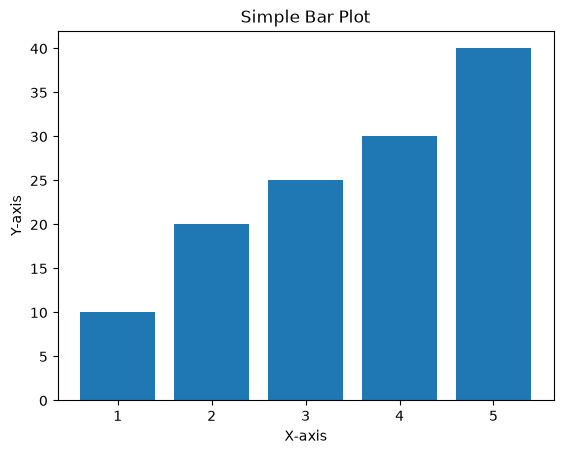

In [ ]:
# working on basic commands 

print("Welcome to Machine Learning Lab")
# Arithmetic
a=20
b=10
print(a+b)

# Loop
for i in range(1,6):
    print(i)

import math
print(math.sqrt(64))

#numpy
import numpy as np
arr=np.array([1,2,3,4,5])
print("array values",arr)
print('adding 5 to each element of the array',arr+5)

#pandas
import pandas as pd
a={'stuname':['raju','rama','sita'],'stuno':[1,2,3],'marks':[90,80,70]}
df=pd.DataFrame(a)
print("dataframe values\n",df)

#Data visualization
import matplotlib.pyplot as plt
x = [1, 2, 3, 4, 5]
y = [10, 20, 25, 30, 40]

plt.bar(x, y)
plt.title('Simple Bar Plot')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.show()


In [ ]:
# applying key preprocessing techniques on the dataset 

import pandas as pd

df=pd.read_csv("student.csv")
df.head()
df.shape
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()
df['age'].fillna(df['age'].median(), inplace=True)

df.dropna(inplace=True)
df.drop_duplicates(inplace=True)
from sklearn.preprocessing import LabelEncoder 
df['sex'] = LabelEncoder().fit_transform(df['sex']) 
df = pd.get_dummies(df, columns=['embarked'], drop_first=True)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   student_id  200 non-null    int64  
 1   sex         200 non-null    object 
 2   age         181 non-null    float64
 3   embarked    182 non-null    object 
 4   grade       200 non-null    int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.9+ KB


C:\Users\rishi\AppData\Local\Temp\ipykernel_15676\1943217563.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(df['age'].median(), inplace=True)


NameError: name 'X' is not defined

In [ ]:

# FIND-S algorithm for finding the most specific hypothesis

import pandas as pd

data = pd.read_csv("enjoysport.csv")
hypothesis = None

for _, row in data.iterrows():
    x = row[:-1].tolist()
    y = row[-1]
    if str(y).lower() == "yes":
        if hypothesis is None:
            hypothesis = x
        else:
            for i in range(len(hypothesis)):
                if hypothesis[i] != x[i]:
                    hypothesis[i] = "?"

print("Most Specific Hypothesis:")
print(hypothesis)


Most Specific Hypothesis:
['sunny', 'warm', '?', 'strong', '?', '?']


C:\Users\rishi\AppData\Local\Temp\ipykernel_15676\713110153.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y = row[-1]


In [ ]:
# implement Candidate Elimination algorithm 

import pandas as pd

data = pd.read_csv("enjoysport.csv")

concepts = data.iloc[:, :-1].values
target = data.iloc[:, -1].values

specific = concepts[0].copy()
general = [["?" for _ in range(len(specific))] for _ in range(len(specific))]

for i, h in enumerate(concepts):
    if target[i].lower() == "yes":
        for x in range(len(specific)):
            if h[x] != specific[x]:
                specific[x] = "?"
                general[x][x] = "?"
    else:
        for x in range(len(specific)):
            if h[x] != specific[x]:
                general[x][x] = specific[x]
            else:
                general[x][x] = "?"

general = [g for g in general if g != ["?"]*len(specific)]

print("Specific Boundary:")
print(specific)
print("\nGeneral Boundary:")
for g in general:
    print(g)




Specific Boundary:
['sunny' 'warm' '?' 'strong' '?' '?']

General Boundary:
['sunny', '?', '?', '?', '?', '?']
['?', 'warm', '?', '?', '?', '?']


In [8]:
# Binary Classification using Logistic Regression

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# Load Dataset
data = pd.read_csv("Social_Network_Ads.csv")

# Select Features
X = data[['Age', 'EstimatedSalary']]

# Target Variable
y = data['Purchased']

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# Create Model
model = LogisticRegression()

# Train Model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Confusion Matrix
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))



Accuracy: 0.88

Confusion Matrix
[[61  2]
 [10 27]]


In [ ]:
# k-Nearest Neighbour algorithm to classify the iris data set

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load Iris Dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

# Train KNN Model
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Predictions
y_pred = knn.predict(X_test)

print("Actual  Predicted")
correct = 0
wrong = 0

for actual, pred in zip(y_test, y_pred):
    print(actual, "      ", pred)
    if actual == pred:
        correct += 1
    else:
        wrong += 1

print("\nCorrect Predictions :", correct)
print("Wrong Predictions   :", wrong)
print("Accuracy :", accuracy_score(y_test, y_pred))


Actual  Predicted
1        1
0        0
2        2
1        1
1        1
0        0
1        1
2        2
1        1
1        1
2        2
0        0
0        0
0        0
0        0
1        1
2        2
1        1
1        1
2        2
0        0
2        2
0        0
2        2
2        2
2        2
2        2
2        2
0        0
0        0
0        0
0        0
1        1
0        0
0        0
2        2
1        1
0        0
0        0
0        0
2        2
1        1
1        1
0        0
0        0

Correct Predictions : 45
Wrong Predictions   : 0
Accuracy : 1.0


In [10]:
# Linear Regression using House Price Dataset

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load Dataset
data = pd.read_csv("HousePrice.csv")

# Independent Variable
X = data[['Area']]

# Dependent Variable
y = data['Price']

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create Model
model = LinearRegression()

# Train Model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

print("Actual Price\tPredicted Price")

for actual, predicted in zip(y_test, y_pred):
    print(actual, "\t", round(predicted,2))

print("\nMean Squared Error :", mean_squared_error(y_test, y_pred))
print("R2 Score :", r2_score(y_test, y_pred))



Actual Price	Predicted Price
2500000 	 2362322.95
3000000 	 2910198.3

Mean Squared Error : 13509658210.883915
R2 Score : 0.7838454686258574


In [1]:
# Logistic Regression using Social Network Ads Dataset

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load Dataset
data = pd.read_csv("Social_Network_Ads.csv")

# Independent Variables
X = data[['Age', 'EstimatedSalary']]

# Dependent Variable
y = data['Purchased']

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train Logistic Regression Model
model = LogisticRegression(random_state=42)

model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Display Actual and Predicted Values
print("Actual\tPredicted")

for actual, predicted in zip(y_test, y_pred):
    print(actual, "\t", predicted)

# Accuracy
print("\nAccuracy Score")
print(accuracy_score(y_test, y_pred))

# Confusion Matrix
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

# Classification Report
print("\nClassification Report")
print(classification_report(y_test, y_pred))


Actual	Predicted
0 	 0
1 	 1
0 	 0
1 	 1
0 	 0
0 	 0
1 	 1
0 	 0
0 	 0
0 	 0
0 	 0
1 	 1
0 	 0
0 	 0
0 	 0
0 	 0
1 	 1
0 	 1
0 	 0
1 	 1
0 	 0
0 	 0
1 	 0
1 	 1
0 	 0
1 	 0
0 	 1
0 	 0
1 	 1
0 	 0
1 	 0
0 	 0
1 	 1
0 	 0
1 	 1
0 	 0
0 	 0
0 	 0
0 	 0
0 	 0
1 	 0
0 	 0
0 	 0
1 	 0
0 	 0
1 	 1
0 	 0
0 	 0
1 	 0
0 	 0
0 	 0
1 	 1
0 	 0
0 	 0
0 	 0
0 	 0
1 	 1
0 	 0
0 	 0
0 	 0
0 	 0
0 	 0
1 	 1
0 	 0
0 	 0
1 	 0
1 	 1
1 	 1
0 	 0
0 	 0
1 	 1
0 	 0
0 	 0
0 	 0
1 	 0
0 	 0
1 	 1
1 	 1
0 	 0
1 	 0
0 	 0
1 	 0
1 	 1
0 	 0
1 	 1
1 	 0
0 	 0
1 	 1
0 	 0
0 	 0
1 	 1
0 	 0
0 	 0
0 	 0
0 	 0
0 	 0
1 	 1
0 	 0
1 	 1
1 	 0

Accuracy Score
0.86

Confusion Matrix
[[61  2]
 [12 25]]

Classification Report
              precision    recall  f1-score   support

           0       0.84      0.97      0.90        63
           1       0.93      0.68      0.78        37

    accuracy                           0.86       100
   macro avg       0.88      0.82      0.84       100
weighted avg       0.87      0

In [ ]:
# SVM for Heart Disease Prediction

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = pd.read_csv("heart.csv")
X = data.drop("target", axis=1)
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25,random_state=42)

scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

model=SVC(kernel="linear",random_state=42)
model.fit(X_train,y_train)

y_pred=model.predict(X_test)

print("Accuracy:",accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))


Accuracy: 0.7898832684824902
[[ 96  36]
 [ 18 107]]
              precision    recall  f1-score   support

           0       0.84      0.73      0.78       132
           1       0.75      0.86      0.80       125

    accuracy                           0.79       257
   macro avg       0.80      0.79      0.79       257
weighted avg       0.80      0.79      0.79       257



In [ ]:
# program for Bias, Variance, Remove duplicates , Cross Validation


# Import libraries
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Load Dataset
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["target"] = iris.target

# Create Duplicate Rows
df = pd.concat([df, df.iloc[:5]], ignore_index=True)

print("Dataset Shape Before Removing Duplicates:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

# Split Dataset

X = df.iloc[:, :-1]
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Decision Tree Model

model = DecisionTreeClassifier(max_depth=3)

model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", accuracy)

# Cross Validation
scores = cross_val_score(model, X, y, cv=5)

print("\nCross Validation Scores:", scores)
print("Average Cross Validation Accuracy:", scores.mean())

# -----------------------------
# Bias and Variance (Simple Explanation)
# -----------------------------
print("\nBias: Error due to overly simple assumptions.")
print("Variance: Error due to model sensitivity to training data.")



Dataset Shape Before Removing Duplicates: (155, 5)
Dataset Shape After Removing Duplicates: (149, 5)

Model Accuracy: 1.0

Cross Validation Scores: [0.96666667 0.96666667 0.93333333 0.93333333 1.        ]
Average Cross Validation Accuracy: 0.96

Bias: Error due to overly simple assumptions.
Variance: Error due to model sensitivity to training data.


In [ ]:
# implement One-hot Encoding.

import pandas as pd

# Sample Dataset
data = {
    "Name": ["Ram", "Sita", "John", "Ravi"],
    "Gender": ["Male", "Female", "Male", "Male"],
    "City": ["Delhi", "Mumbai", "Delhi", "Chennai"]
}

df = pd.DataFrame(data)

print("Original Dataset")
print(df)

# One-Hot Encoding
encoded_df = pd.get_dummies(df, columns=["Gender", "City"])

print("\nOne-Hot Encoded Dataset")
print(encoded_df)



Original Dataset
   Name  Gender     City
0   Ram    Male    Delhi
1  Sita  Female   Mumbai
2  John    Male    Delhi
3  Ravi    Male  Chennai

One-Hot Encoded Dataset
   Name  Gender_Female  Gender_Male  City_Chennai  City_Delhi  City_Mumbai
0   Ram          False         True         False        True        False
1  Sita           True        False         False       False         True
2  John          False         True         False        True        False
3  Ravi          False         True          True       False        False


In [ ]:
# implement Categorical Encoding.

import pandas as pd
from sklearn.preprocessing import LabelEncoder
# Sample Dataset
data = {
    "Name": ["Ram", "Sita", "John", "Ravi"],
    "Department": ["CSE", "ECE", "EEE", "CSE"]
}
df = pd.DataFrame(data)
print("Original Dataset")
print(df)

# Label Encoding
encoder = LabelEncoder()
df["Department_Encoded"] = encoder.fit_transform(df["Department"])
print("\nEncoded Dataset")
print(df)
print("\nCategory Mapping")
for category, value in zip(encoder.classes_, encoder.transform(encoder.classes_)):
    print(category, "->", value)


Original Dataset
   Name Department
0   Ram        CSE
1  Sita        ECE
2  John        EEE
3  Ravi        CSE

Encoded Dataset
   Name Department  Department_Encoded
0   Ram        CSE                   0
1  Sita        ECE                   1
2  John        EEE                   2
3  Ravi        CSE                   0

Category Mapping
CSE -> 0
ECE -> 1
EEE -> 2


In [ ]:
# Random Forest classifier

# Import required libraries

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
iris = load_iris()

X = iris.data
y = iris.target

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.3, random_state=42
)

# Create Random Forest model
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train model
rf.fit(X_train, y_train)

# Predict
y_pred = rf.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Feature Importance
print("\nFeature Importance:")
for feature, importance in zip(iris.feature_names, rf.feature_importances_):
    print(f"{feature}: {importance:.4f}")



Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45


Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

Feature Importance:
sepal length (cm): 0.1041
sepal width (cm): 0.0446
petal length (cm): 0.4173
petal width (cm): 0.4340
